# UTS Sistem Cerdas — Soal 1: FIS Mamdani, Sistem Pakar, dan XGBoost
**Studi kasus:** deteksi dini risiko stunting balita, Puskesmas Harapan Sehat

Nama: Muhammad Aldi Almi |  NIM: 2411002  |  Kelas: Informatika 24

## Dataset dan lampiran (ringkas)
Dua file CSV, masing-masing 200 baris **data sintetis/simulasi** (bukan rekam medis, bukan untuk keputusan kesehatan nyata). Kedua dataset memiliki ID dan urutan subjek yang sama.

| Dataset | Dipakai untuk | Kolom target |
|---|---|---|
| `Dataset_A_FIS_SistemPakar_200.csv` | Soal 1a (FIS) dan 1b (Sistem Pakar) | `Status_gizi`: Normal / Gizi Kurang / Stunting |
| `Dataset_B_XGBoost_200.csv` | Soal 1c (XGBoost) | `Label_risiko`: 0 (Normal) / 1 (Risiko) |

Fitur: `Umur_bulan`, `BB_kg`, `TB_cm`, `LILA_cm`, `Jenis_kelamin`, `ASI_eksklusif_6_bulan` (kolom `ID` dan `Nama` tidak dipakai sebagai fitur).



In [2]:
# Hubungkan Google Drive dan masuk ke folder tempat CSV disimpan
import os, glob
FOLDER = "/content/drive/MyDrive/UTS_XGBoost_DecisionTree"   # <- ganti sesuai lokasi folder kamu di Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(FOLDER)
except ImportError:
    pass  # bukan di Colab: pastikan file CSV ada di folder yang sama dengan notebook
print("Isi folder:", os.listdir())

def cari(prefix):
    hit = sorted(glob.glob(f"{prefix}*.csv"))
    assert hit, f"File {prefix}*.csv tidak ditemukan di {os.getcwd()}"
    return hit[0]

FILE_A, FILE_B = cari("Dataset_A"), cari("Dataset_B")   # nama berakhiran _1 pun terbaca
print("Dataset A:", FILE_A, "| Dataset B:", FILE_B)

Mounted at /content/drive
Isi folder: ['Dataset_B_XGBoost_200.csv', 'Dataset_A_FIS_SistemPakar_200.csv']
Dataset A: Dataset_A_FIS_SistemPakar_200.csv | Dataset B: Dataset_B_XGBoost_200.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
WARNA = {"Normal": "#2a9d8f", "Gizi Kurang": "#e9c46a", "Stunting": "#e76f51"}

A = pd.read_csv(FILE_A, encoding="utf-8-sig")
B = pd.read_csv(FILE_B, encoding="utf-8-sig")
assert (A["ID"].values == B["ID"].values).all(), "ID/urutan Dataset A dan B harus sama"

df = A.rename(columns={"Umur_bulan": "umur", "BB_kg": "bb", "TB_cm": "tb", "LILA_cm": "lila"}).copy()
df["asi"]  = (df["ASI_eksklusif_6_bulan"].astype(str).str.strip().str.lower() == "ya").astype(int)
df["jk"]   = np.where(df["Jenis_kelamin"].astype(str).str.lower().str.startswith("l"), "L", "P")
df["jk_l"] = (df["jk"] == "L").astype(int)                       # 1 = laki-laki
df["y"]    = B["Label_risiko"].astype(str).str.strip().str[0].astype(int).values   # ground truth (Dataset B)
assert ((df["Status_gizi"] != "Normal").astype(int) == df["y"]).all()

FITUR = ["umur", "bb", "tb", "lila", "jk_l", "asi"]
X, y = df[FITUR], df["y"]

# Satu split untuk SEMUA model (80:20, stratified, random_state=42)
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, stratify=y, random_state=42)
Xtr, Xte, ytr, yte = X.loc[idx_tr], X.loc[idx_te], y.loc[idx_tr], y.loc[idx_te]
te = df.loc[idx_te].copy()

print(df[["ID", "Nama", "umur", "bb", "tb", "lila", "Jenis_kelamin", "ASI_eksklusif_6_bulan", "Status_gizi"]].head(8).to_string(index=False))
print("\nJumlah data:", len(df), "| latih:", len(Xtr), "| uji:", len(Xte))
print("\nStatus gizi (Dataset A):\n", df["Status_gizi"].value_counts().to_string())
print("\nLabel risiko (Dataset B):\n", df["y"].value_counts().rename({0: "0 (Normal)", 1: "1 (Risiko)"}).to_string())
display(df[["umur", "bb", "tb", "lila"]].describe().round(2))

 ID           Nama  umur   bb   tb  lila Jenis_kelamin ASI_eksklusif_6_bulan Status_gizi
B01   Andi Pratama    24 10.2 82.0  13.5     Laki-laki                    Ya      Normal
B02    Siti Rahayu    36 11.8 88.0  12.1     Perempuan                 Tidak Gizi Kurang
B03   Budi Santoso    18  7.4 74.0  11.0     Laki-laki                 Tidak    Stunting
B04 Lena Wulandari    48 15.1 96.0  14.2     Perempuan                    Ya      Normal
B05   Rizky Aditya    12  6.8 68.0  10.5     Laki-laki                 Tidak    Stunting
B06    Dewi Kusuma    30  9.5 80.0  12.8     Perempuan                 Tidak Gizi Kurang
B07   Farhan Malik    42 13.2 93.0  13.9     Laki-laki                    Ya      Normal
B08     Nur Aisyah     6  5.1 61.0  11.8     Perempuan                 Tidak Gizi Kurang

Jumlah data: 200 | latih: 160 | uji: 40

Status gizi (Dataset A):
 Status_gizi
Normal         124
Gizi Kurang     41
Stunting        35

Label risiko (Dataset B):
 y
0 (Normal)    124
1 (Risiko)    

,umur,bb,tb,lila
count,200.00,200.00,200.00,200.00
mean,27.23,7.37,72.16,11.68
std,16.77,3.54,13.41,1.58
min,0.00,2.20,47.50,8.20
25%,12.00,4.60,61.75,10.50
50%,25.50,6.80,71.80,11.80
75%,40.00,9.93,82.58,12.90
max,59.00,16.50,101.20,15.40


## Eksplorasi data (grafik)

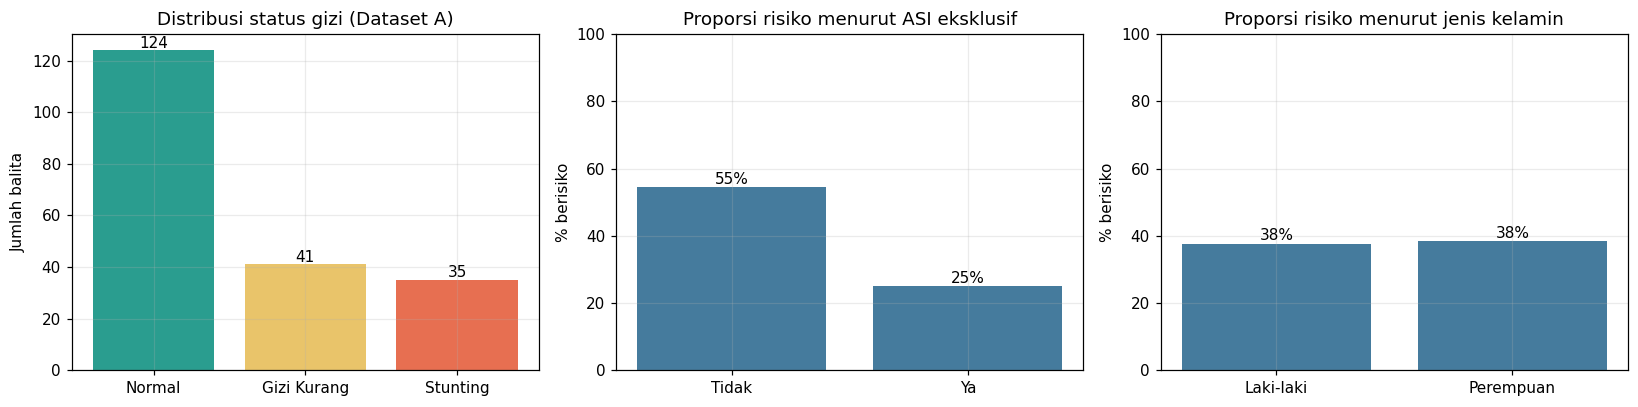

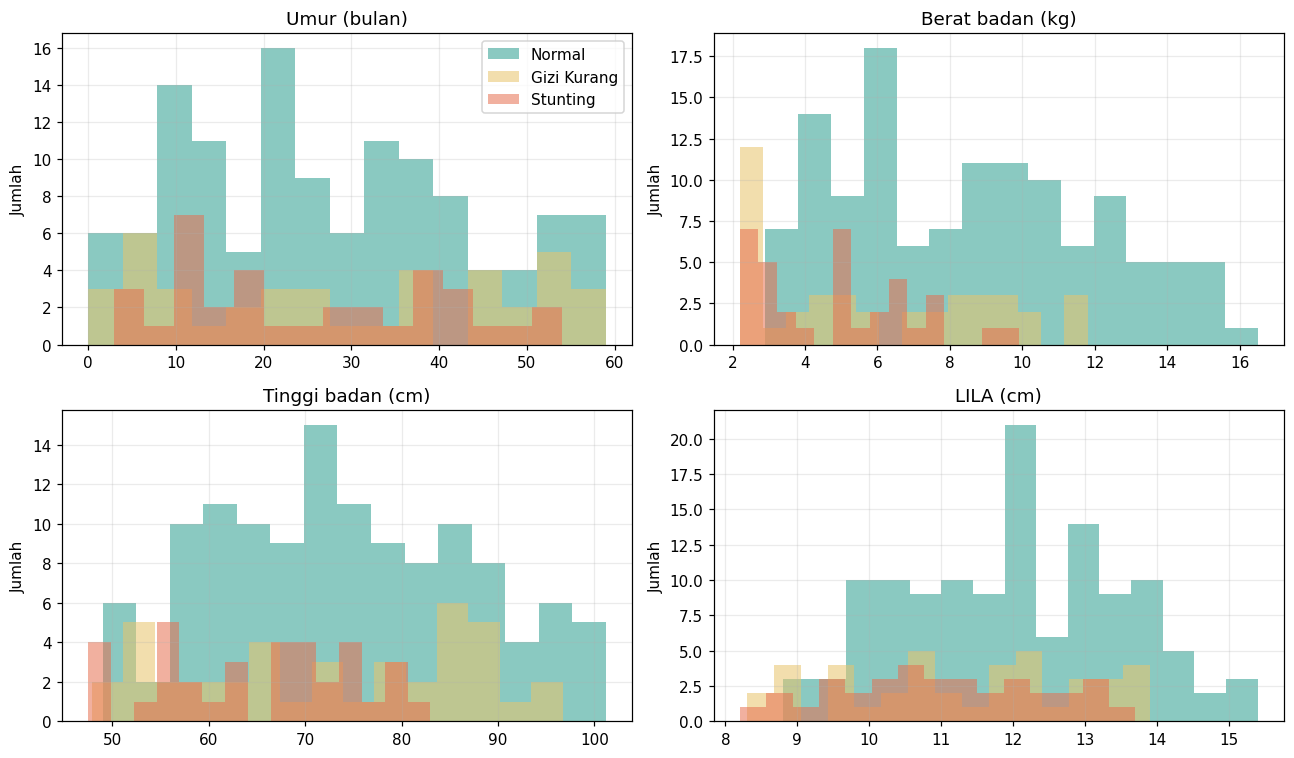

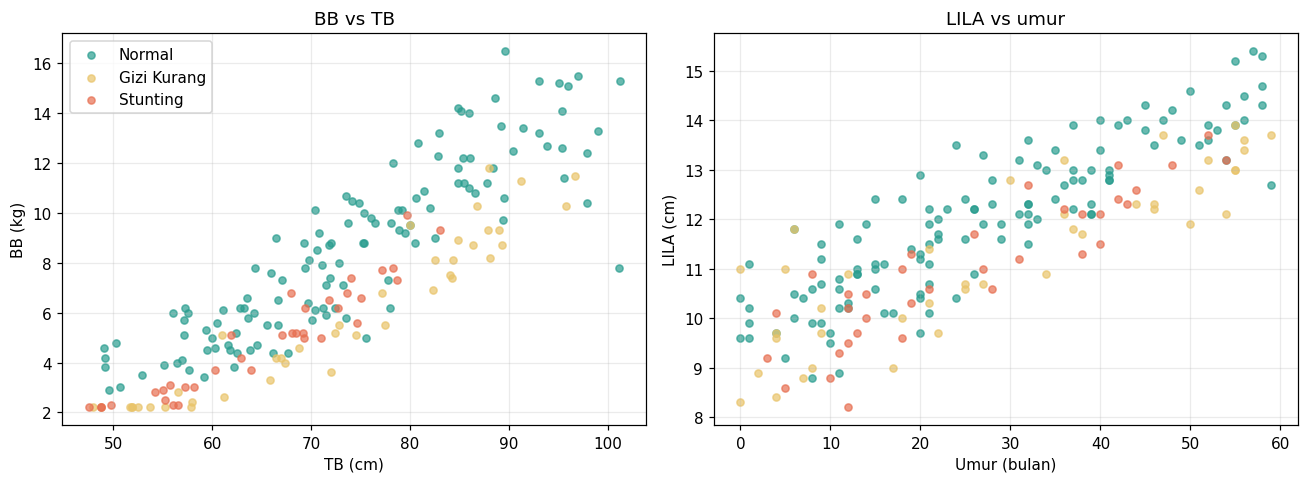

In [4]:
# Grafik 1: distribusi kelas, ASI, dan jenis kelamin terhadap risiko
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
vc = df["Status_gizi"].value_counts().reindex(["Normal", "Gizi Kurang", "Stunting"])
ax[0].bar(vc.index, vc.values, color=[WARNA[k] for k in vc.index])
for i, v in enumerate(vc.values): ax[0].text(i, v + 1, str(v), ha="center")
ax[0].set_title("Distribusi status gizi (Dataset A)"); ax[0].set_ylabel("Jumlah balita")

for a, kol, judul in [(ax[1], "ASI_eksklusif_6_bulan", "Proporsi risiko menurut ASI eksklusif"),
                      (ax[2], "Jenis_kelamin", "Proporsi risiko menurut jenis kelamin")]:
    p = df.groupby(kol)["y"].mean() * 100
    a.bar(p.index, p.values, color="#457b9d")
    for i, v in enumerate(p.values): a.text(i, v + 1, f"{v:.0f}%", ha="center")
    a.set_title(judul); a.set_ylabel("% berisiko"); a.set_ylim(0, 100)
plt.tight_layout(); plt.show()

# Grafik 2: sebaran fitur numerik per status gizi
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for a, kol, nama in zip(ax.ravel(), ["umur", "bb", "tb", "lila"],
                        ["Umur (bulan)", "Berat badan (kg)", "Tinggi badan (cm)", "LILA (cm)"]):
    for k in ["Normal", "Gizi Kurang", "Stunting"]:
        a.hist(df.loc[df["Status_gizi"] == k, kol], bins=15, alpha=0.55, label=k, color=WARNA[k])
    a.set_title(nama); a.set_ylabel("Jumlah")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

# Grafik 3: hubungan fitur
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k in ["Normal", "Gizi Kurang", "Stunting"]:
    d = df[df["Status_gizi"] == k]
    ax[0].scatter(d["tb"], d["bb"], s=22, alpha=0.7, label=k, color=WARNA[k])
    ax[1].scatter(d["umur"], d["lila"], s=22, alpha=0.7, label=k, color=WARNA[k])
ax[0].set_xlabel("TB (cm)"); ax[0].set_ylabel("BB (kg)"); ax[0].set_title("BB vs TB"); ax[0].legend()
ax[1].set_xlabel("Umur (bulan)"); ax[1].set_ylabel("LILA (cm)"); ax[1].set_title("LILA vs umur")
plt.tight_layout(); plt.show()

# Bagian 1 — Soal 1c: XGBoost vs Decision Tree
Target `Label_risiko`; fitur: umur, BB, TB, LILA, jenis kelamin, ASI eksklusif. Tuning 5 hyperparameter memakai GridSearchCV dengan Stratified 5-Fold (skor F1) **hanya pada data latih**.

In [5]:
# Tuning XGBoost: GridSearchCV + Stratified 5-Fold CV
param_grid = {
    "n_estimators":     [50, 100],
    "learning_rate":    [0.03, 0.1],
    "max_depth":        [1, 2, 3],
    "subsample":        [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(XGBClassifier(eval_metric="logloss", random_state=42),
                    param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(Xtr, ytr)

tabel_hp = pd.DataFrame({
    "Parameter": list(param_grid),
    "Nilai dicoba": [str(v) for v in param_grid.values()],
    "Nilai terbaik": [grid.best_params_[k] for k in param_grid],
    "Metode tuning": "GridSearchCV + Stratified 5-Fold (skor F1)",
})
display(tabel_hp)
print(f"F1 rata-rata CV terbaik: {grid.best_score_:.3f}")

hasil_cv = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
display(hasil_cv.sort_values("rank_test_score").head(5).round(3).reset_index(drop=True))

,Parameter,Nilai dicoba,Nilai terbaik,Metode tuning
0,n_estimators,"[50, 100]",100.0,GridSearchCV + Stratified 5-Fold (skor F1)
1,learning_rate,"[0.03, 0.1]",0.1,GridSearchCV + Stratified 5-Fold (skor F1)
2,max_depth,"[1, 2, 3]",2.0,GridSearchCV + Stratified 5-Fold (skor F1)
3,subsample,"[0.8, 1.0]",1.0,GridSearchCV + Stratified 5-Fold (skor F1)
4,colsample_bytree,"[0.8, 1.0]",1.0,GridSearchCV + Stratified 5-Fold (skor F1)


F1 rata-rata CV terbaik: 0.878


,params,mean_test_score,std_test_score,rank_test_score
0,"{'colsample_bytree': 1.0, 'learning_rate': 0.1...",0.878,0.043,1
1,"{'colsample_bytree': 1.0, 'learning_rate': 0.1...",0.860,0.038,2
2,"{'colsample_bytree': 1.0, 'learning_rate': 0.1...",0.853,0.051,3
3,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...",0.853,0.051,3
4,"{'colsample_bytree': 1.0, 'learning_rate': 0.1...",0.853,0.051,3


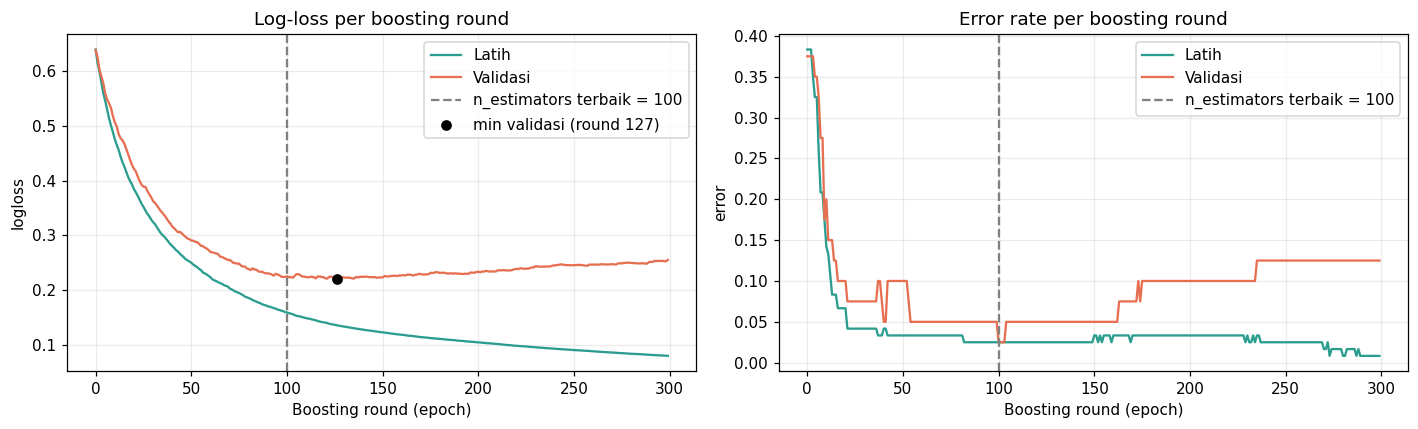

In [6]:
# Kurva per boosting round (padanan "epoch" pada XGBoost)
# Diagnostik: validasi diambil dari DATA LATIH (data uji tidak disentuh); model akhir tetap grid.best_estimator_
Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=0.25, stratify=ytr, random_state=42)
RONDE = 300
m_curve = XGBClassifier(**{**grid.best_params_, "n_estimators": RONDE},
                        eval_metric=["logloss", "error"], random_state=42)
m_curve.fit(Xa, ya, eval_set=[(Xa, ya), (Xv, yv)], verbose=False)
ev = m_curve.evals_result()
best_n = grid.best_params_["n_estimators"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, metrik, judul in [(ax[0], "logloss", "Log-loss per boosting round"),
                         (ax[1], "error", "Error rate per boosting round")]:
    a.plot(ev["validation_0"][metrik], label="Latih", color="#2a9d8f")
    a.plot(ev["validation_1"][metrik], label="Validasi", color="#e76f51")
    a.axvline(best_n, color="gray", ls="--", label=f"n_estimators terbaik = {best_n}")
    if metrik == "logloss":
        i = int(np.argmin(ev["validation_1"][metrik]))
        a.scatter([i], [ev["validation_1"][metrik][i]], color="black", zorder=5, label=f"min validasi (round {i+1})")
    a.set_xlabel("Boosting round (epoch)"); a.set_ylabel(metrik); a.set_title(judul); a.legend()
plt.tight_layout(); plt.show()

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
XGBoost (Tuned),85.0,90.9,66.7,76.9,84.7
Decision Tree (Baseline),77.5,87.5,46.7,60.9,79.6


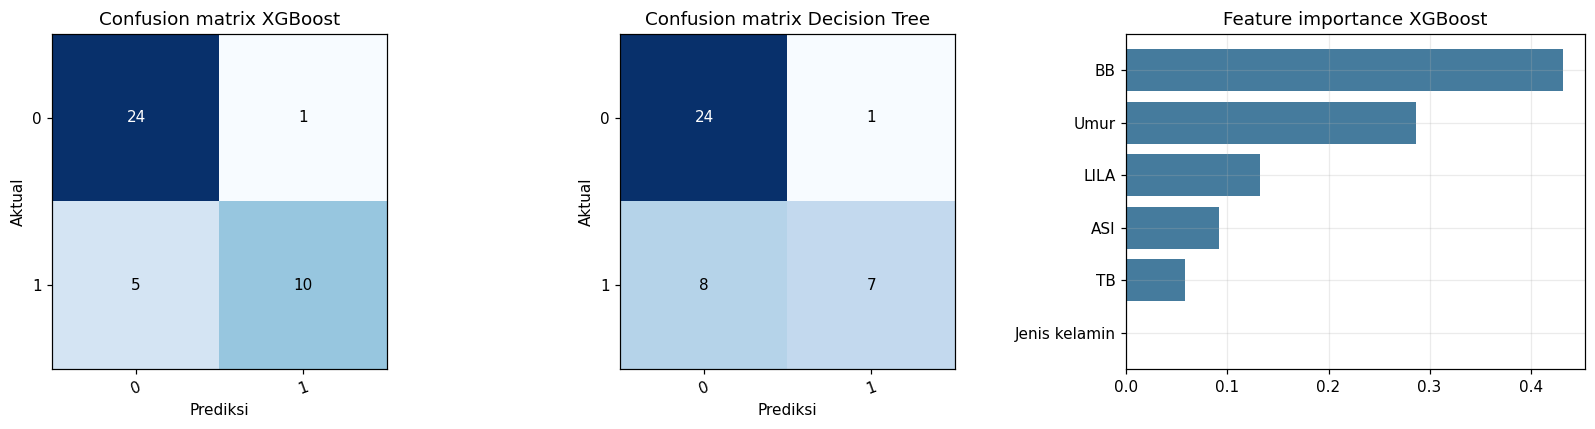

In [7]:
# Evaluasi akhir di data uji: XGBoost (tuned) vs Decision Tree (baseline)
xgb_best = grid.best_estimator_
dt = DecisionTreeClassifier(max_depth=4, random_state=42).fit(Xtr, ytr)

def hitung_metrik(ytrue, pred, skor):
    return {"Accuracy": accuracy_score(ytrue, pred), "Precision": precision_score(ytrue, pred, zero_division=0),
            "Recall": recall_score(ytrue, pred, zero_division=0), "F1-Score": f1_score(ytrue, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(ytrue, skor)}

HASIL, SKOR, PRED = {}, {}, {}
for nama, mdl in [("XGBoost (Tuned)", xgb_best), ("Decision Tree (Baseline)", dt)]:
    PRED[nama], SKOR[nama] = mdl.predict(Xte), mdl.predict_proba(Xte)[:, 1]
    HASIL[nama] = hitung_metrik(yte, PRED[nama], SKOR[nama])
display((pd.DataFrame(HASIL).T * 100).round(1))

def plot_cm(a, ytrue, pred, labels, judul):
    cm = confusion_matrix(ytrue, pred, labels=labels)
    a.imshow(cm, cmap="Blues"); a.grid(False)
    a.set_xticks(range(len(labels))); a.set_xticklabels(labels, rotation=20)
    a.set_yticks(range(len(labels))); a.set_yticklabels(labels)
    a.set_xlabel("Prediksi"); a.set_ylabel("Aktual"); a.set_title(judul)
    for i in range(len(labels)):
        for j in range(len(labels)):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plot_cm(ax[0], yte, PRED["XGBoost (Tuned)"], [0, 1], "Confusion matrix XGBoost")
plot_cm(ax[1], yte, PRED["Decision Tree (Baseline)"], [0, 1], "Confusion matrix Decision Tree")
imp = pd.Series(xgb_best.feature_importances_, index=["Umur", "BB", "TB", "LILA", "Jenis kelamin", "ASI"]).sort_values()
ax[2].barh(imp.index, imp.values, color="#457b9d"); ax[2].set_title("Feature importance XGBoost")
plt.tight_layout(); plt.show()

# Bagian 2 — Soal 1a dan 1b: FIS Mamdani dan Sistem Pakar
Alur: z-score BB/U dan TB/U -> **FIS Mamdani** (2 input, output skor risiko 0–100) -> **Sistem Pakar** memvalidasi memakai skor FIS + LILA + ASI -> diagnosa dan rekomendasi.

**Penting:** parameter fungsi keanggotaan dan basis rule di bawah adalah nilai awal. Samakan dengan rancangan 1a dan 1b milikmu sendiri.

Memakai tabel referensi bawaan: ESTIMASI pembelajaran, BUKAN tabel resmi WHO
Sumber referensi z-score: who


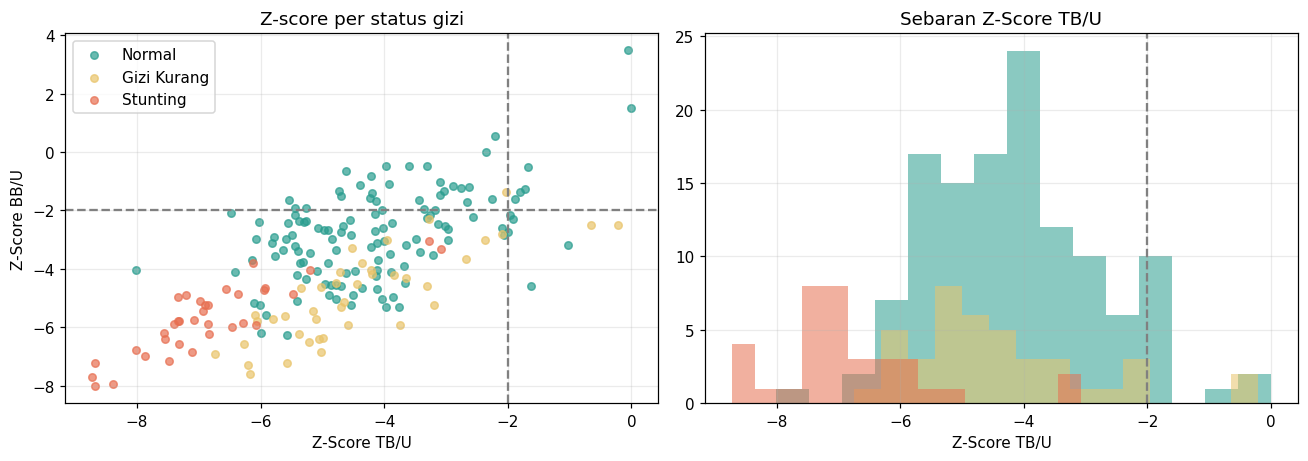

In [8]:
# ============ Z-SCORE BB/U dan TB/U ============
if os.path.exists("who_ref.csv"):
    who = pd.read_csv("who_ref.csv")       # kolom: umur,(jk),bb_median,bb_sd,tb_median,tb_sd
    print("Memakai who_ref.csv")
    if "jk" not in who.columns:
        who = pd.concat([who.assign(jk="L"), who.assign(jk="P")])
else:
    # Tabel bawaan: ESTIMASI pembelajaran (bukan tabel resmi WHO). Ganti dengan tabel resmi dari dosen bila ada.
    umur_ref = [0, 1, 2, 3, 6, 9, 12, 18, 24, 36, 48, 60]
    who = pd.concat([
        pd.DataFrame({"umur": umur_ref, "jk": "L",
            "bb_median": [3.3,4.5,5.6,6.4,7.9,8.9,9.6,10.9,12.2,14.3,16.3,18.3],
            "bb_sd":     [0.42,0.55,0.65,0.70,0.80,0.88,0.92,1.05,1.25,1.50,1.80,2.10],
            "tb_median": [49.9,54.7,58.4,61.4,67.6,72.0,75.7,82.3,87.1,96.1,103.3,110.0],
            "tb_sd":     [1.9,2.0,2.1,2.15,2.2,2.3,2.35,2.7,2.7,3.6,4.2,4.6]}),
        pd.DataFrame({"umur": umur_ref, "jk": "P",
            "bb_median": [3.2,4.2,5.1,5.8,7.3,8.2,8.9,10.2,11.5,13.9,16.1,18.2],
            "bb_sd":     [0.40,0.50,0.60,0.65,0.78,0.85,0.92,1.05,1.25,1.55,1.90,2.25],
            "tb_median": [49.1,53.7,57.1,59.8,65.7,70.1,74.0,80.7,85.7,95.1,102.7,109.4],
            "tb_sd":     [1.85,1.95,2.05,2.1,2.25,2.4,2.55,2.7,2.85,3.5,4.0,4.5]}),
    ])
    print("Memakai tabel referensi bawaan: ESTIMASI pembelajaran, BUKAN tabel resmi WHO")

def zscore_who(data):
    z_bb, z_tb = np.zeros(len(data)), np.zeros(len(data))
    for jk in ["L", "P"]:
        m = (data["jk"] == jk).values
        w = who[who["jk"] == jk].sort_values("umur")
        u = data.loc[m, "umur"]
        z_bb[m] = (data.loc[m, "bb"] - np.interp(u, w["umur"], w["bb_median"])) / np.interp(u, w["umur"], w["bb_sd"])
        z_tb[m] = (data.loc[m, "tb"] - np.interp(u, w["umur"], w["tb_median"])) / np.interp(u, w["umur"], w["tb_sd"])
    return z_bb, z_tb

# Alternatif: referensi dari anak Normal pada data latih (regresi linear terhadap umur, per jenis kelamin)
norm_tr = df.loc[idx_tr][df.loc[idx_tr, "Status_gizi"] == "Normal"]
ref_data = {}
for jk in ["L", "P"]:
    d = norm_tr[norm_tr["jk"] == jk]
    for kol in ["bb", "tb"]:
        koef = np.polyfit(d["umur"], d[kol], 1)
        ref_data[(jk, kol)] = (koef, (d[kol] - np.polyval(koef, d["umur"])).std(ddof=2))

def zscore_data(data):
    z = {}
    for kol in ["bb", "tb"]:
        z[kol] = np.array([(r[kol] - np.polyval(ref_data[(r["jk"], kol)][0], r["umur"])) / ref_data[(r["jk"], kol)][1]
                           for _, r in data.iterrows()])
    return z["bb"], z["tb"]

REFERENSI = "who"    # "who" = tabel referensi di atas (estimasi / resmi dari dosen) | "data" = referensi dari anak Normal data latih
zscore = zscore_who if REFERENSI == "who" else zscore_data
df["z_bb"], df["z_tb"] = zscore(df)
print("Sumber referensi z-score:", REFERENSI)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for k in ["Normal", "Gizi Kurang", "Stunting"]:
    d = df[df["Status_gizi"] == k]
    ax[0].scatter(d["z_tb"], d["z_bb"], s=24, alpha=0.7, label=k, color=WARNA[k])
ax[0].axvline(-2, color="gray", ls="--"); ax[0].axhline(-2, color="gray", ls="--")
ax[0].set_xlabel("Z-Score TB/U"); ax[0].set_ylabel("Z-Score BB/U"); ax[0].set_title("Z-score per status gizi"); ax[0].legend()
for k in ["Normal", "Gizi Kurang", "Stunting"]:
    ax[1].hist(df.loc[df["Status_gizi"] == k, "z_tb"], bins=15, alpha=0.55, color=WARNA[k], label=k)
ax[1].axvline(-2, color="gray", ls="--"); ax[1].set_xlabel("Z-Score TB/U"); ax[1].set_title("Sebaran Z-Score TB/U")
plt.tight_layout(); plt.show()

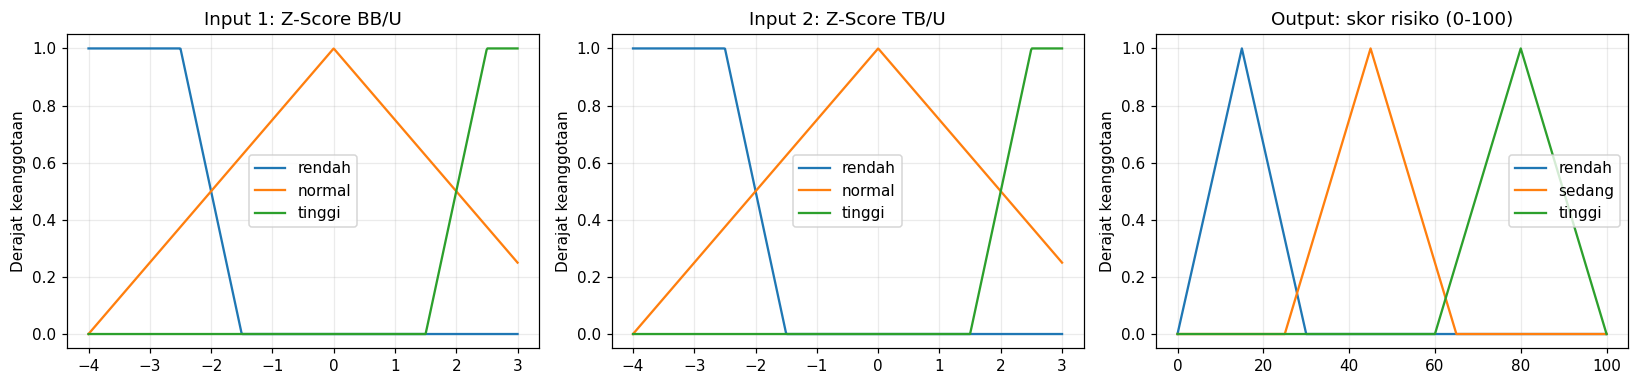

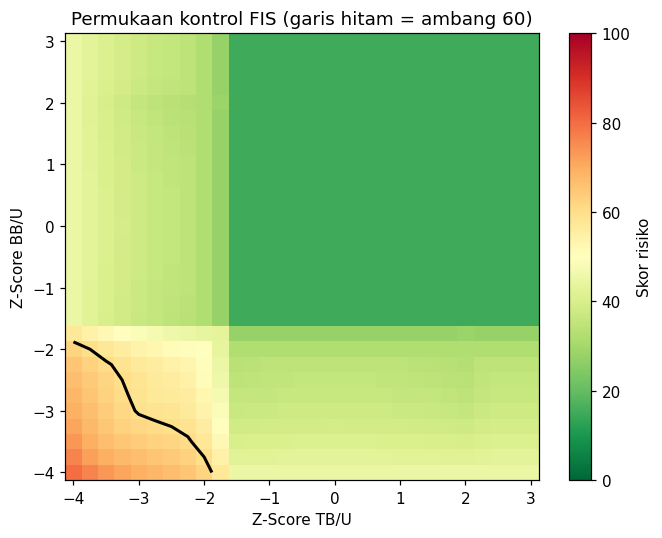

In [9]:
# ============ 1a. FIS MAMDANI (2 input: z BB/U dan z TB/U) ============
# --- PARAMETER FUNGSI KEANGGOTAAN: samakan dengan tabel 1a(i) milikmu ---
# 3 angka = segitiga (a, b, c); 4 angka = trapesium (a, b, c, d)
MF_Z = {                                   # BB/U maupun TB/U (range -4 s.d. +3)
    "rendah": (-4, -4, -2.5, -1.5),
    "normal": (-4, 0, 4),
    "tinggi": (1.5, 2.5, 3, 3),
}
MF_OUT = {                                 # skor risiko 0-100
    "rendah": (0, 15, 30),
    "sedang": (25, 45, 65),
    "tinggi": (60, 80, 100),
}
# --- BASIS RULE: (himpunan BB/U, himpunan TB/U) -> himpunan skor. Samakan dengan 1a(ii) ---
RULES_FIS = [
    ("rendah", "rendah", "tinggi"),
    ("rendah", "normal", "sedang"),
    ("rendah", "tinggi", "sedang"),
    ("normal", "rendah", "sedang"),
    ("normal", "normal", "rendah"),
    ("normal", "tinggi", "rendah"),
    ("tinggi", "rendah", "sedang"),
    ("tinggi", "normal", "rendah"),
    ("tinggi", "tinggi", "rendah"),
]
AMBANG = 60   # skor >= AMBANG -> kelas Risiko (1). Contoh dosen: 60. Bila dosen tidak menetapkan, nyatakan dan benarkan ambangmu di laporan

def mf(x, p):
    x = np.asarray(x, dtype=float)
    a, b, c, d = (p[0], p[1], p[1], p[2]) if len(p) == 3 else p
    kiri  = np.where(b > a, (x - a) / (b - a + 1e-12), (x >= b).astype(float))
    kanan = np.where(d > c, (d - x) / (d - c + 1e-12), (x <= c).astype(float))
    return np.clip(np.minimum(kiri, kanan), 0, 1)

U = np.linspace(0, 100, 1001)               # semesta output (resolusi 0,1)

def fis_mamdani(z_bb, z_tb, detail=False, plot=False):
    z_bb, z_tb = float(np.clip(z_bb, -4, 3)), float(np.clip(z_tb, -4, 3))
    mu_bb = {k: float(mf(z_bb, p)) for k, p in MF_Z.items()}      # fuzzifikasi
    mu_tb = {k: float(mf(z_tb, p)) for k, p in MF_Z.items()}
    alpha, aktif = {}, []
    for i, (b, t, o) in enumerate(RULES_FIS, 1):
        a = min(mu_bb[b], mu_tb[t])                               # AND = min
        if a > 0:
            aktif.append((f"R{i}", b, t, o, a))
        alpha[o] = max(alpha.get(o, 0), a)                        # agregasi per output = max
    agg = np.zeros_like(U)
    for o, a in alpha.items():
        agg = np.maximum(agg, np.minimum(a, mf(U, MF_OUT[o])))    # alpha-cut lalu agregasi
    skor = 0.0 if agg.sum() == 0 else float((U * agg).sum() / agg.sum())   # centroid
    if detail:
        print(f"z_BB = {z_bb:.2f}, z_TB = {z_tb:.2f}")
        print("Fuzzifikasi BB/U:", {k: round(v, 3) for k, v in mu_bb.items()})
        print("Fuzzifikasi TB/U:", {k: round(v, 3) for k, v in mu_tb.items()})
        for r in aktif:
            print(f"  {r[0]}: BB {r[1]} AND TB {r[2]} -> skor {r[3]}  (alpha = {r[4]:.3f})")
        print("Alpha per output:", {k: round(v, 3) for k, v in alpha.items()})
        print(f"Skor risiko (centroid) = {skor:.2f}")
    if plot:
        plt.figure(figsize=(7, 3.4))
        for o, p in MF_OUT.items():
            plt.plot(U, mf(U, p), ls=":", color="gray")
        plt.fill_between(U, agg, color="#e76f51", alpha=0.45, label="Hasil agregasi (setelah alpha-cut)")
        plt.axvline(skor, color="black", label=f"Centroid = {skor:.1f}")
        plt.xlabel("Skor risiko"); plt.ylabel("Derajat keanggotaan"); plt.legend(); plt.title("Defuzzifikasi centroid")
        plt.tight_layout(); plt.show()
    return skor

def jelaskan_fis(z_bb, z_tb):
    # Alat bantu: cek hitungan manual 1a(iii) dengan z-score hasil hitunganmu sendiri
    return fis_mamdani(z_bb, z_tb, detail=True, plot=True)

# --- Grafik fungsi keanggotaan dan permukaan kontrol FIS ---
zz = np.linspace(-4, 3, 500)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, p in MF_Z.items():
    ax[0].plot(zz, mf(zz, p), label=k); ax[1].plot(zz, mf(zz, p), label=k)
for k, p in MF_OUT.items():
    ax[2].plot(U, mf(U, p), label=k)
ax[0].set_title("Input 1: Z-Score BB/U"); ax[1].set_title("Input 2: Z-Score TB/U"); ax[2].set_title("Output: skor risiko (0-100)")
for a in ax: a.set_ylabel("Derajat keanggotaan"); a.legend()
plt.tight_layout(); plt.show()

g = np.linspace(-4, 3, 29)
perm = np.array([[fis_mamdani(b, t) for t in g] for b in g])
plt.figure(figsize=(6.2, 5))
cs = plt.pcolormesh(g, g, perm, cmap="RdYlGn_r", shading="auto", vmin=0, vmax=100)
plt.colorbar(cs, label="Skor risiko")
plt.contour(g, g, perm, levels=[AMBANG], colors="black", linewidths=2)
plt.xlabel("Z-Score TB/U"); plt.ylabel("Z-Score BB/U")
plt.title(f"Permukaan kontrol FIS (garis hitam = ambang {AMBANG})"); plt.grid(False)
plt.tight_layout(); plt.show()

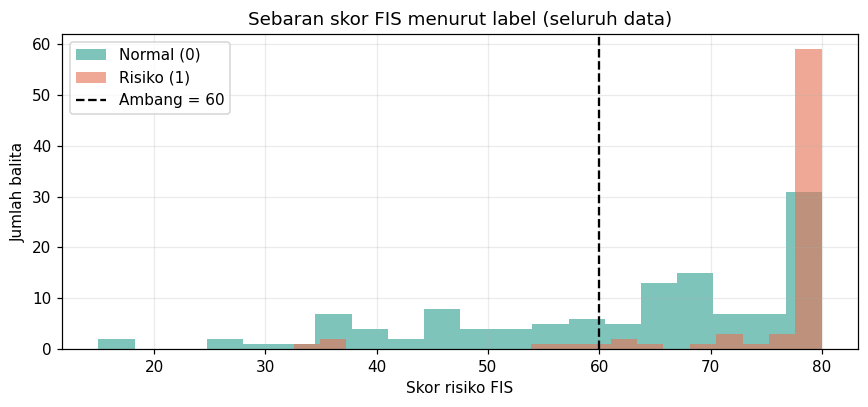

In [10]:
# Terapkan FIS ke seluruh data (metrik tetap dihitung hanya pada data uji)
df["skor_fis"] = [fis_mamdani(a, b) for a, b in zip(df["z_bb"], df["z_tb"])]
df["pred_fis"] = (df["skor_fis"] >= AMBANG).astype(int)
te = df.loc[idx_te].copy()

plt.figure(figsize=(8, 3.8))
plt.hist(df.loc[df["y"] == 0, "skor_fis"], bins=20, alpha=0.6, color=WARNA["Normal"], label="Normal (0)")
plt.hist(df.loc[df["y"] == 1, "skor_fis"], bins=20, alpha=0.6, color=WARNA["Stunting"], label="Risiko (1)")
plt.axvline(AMBANG, color="black", ls="--", label=f"Ambang = {AMBANG}")
plt.xlabel("Skor risiko FIS"); plt.ylabel("Jumlah balita"); plt.title("Sebaran skor FIS menurut label (seluruh data)"); plt.legend()
plt.tight_layout(); plt.show()

In [11]:
# ============ 1b. SISTEM PAKAR (rule IF-THEN + forward chaining) ============
# Fakta simbolik (WM awal) hanya dari data yang tersedia di Dataset A + skor FIS (berat lahir tidak dipakai)
def buat_fakta(z_bb, z_tb, lila, asi, skor):
    f = set()
    f.add("tb_pendek" if z_tb < -2 else "tb_normal")
    f.add("bb_kurang" if z_bb < -2 else "bb_normal")
    f.add("lila_kurang" if lila < 11.5 else "lila_cukup")
    f.add("asi_ya" if asi == 1 else "asi_tidak")
    f.add("skor_tinggi" if skor >= 60 else "skor_sedang" if skor >= 40 else "skor_rendah")
    return f

# (id, kondisi (semua harus ada di WM), fakta hasil, rekomendasi) -> samakan dengan rancangan 1b(i)
RULES_PAKAR = [
    ("R1", {"skor_tinggi", "tb_pendek"},               "dx_stunting",    "Rujuk ke Puskesmas/dokter anak, beri PMT, pantau TB tiap bulan"),
    ("R2", {"skor_sedang", "tb_pendek"},               "dx_stunting",    "Pantau TB dan BB tiap bulan, edukasi gizi, evaluasi 1 bulan lagi"),
    ("R3", {"skor_tinggi", "bb_kurang", "tb_normal"},  "dx_gizi_kurang", "Beri PMT, konsultasi gizi, timbang tiap 2 minggu"),
    ("R4", {"bb_kurang", "lila_kurang"},               "dx_gizi_kurang", "Beri PMT pemulihan, ukur LILA tiap bulan"),
    ("R5", {"skor_sedang", "asi_tidak", "tb_normal"},  "dx_gizi_kurang", "Edukasi MP-ASI dan pola makan, pantau 1 bulan"),
    ("R6", {"lila_kurang", "tb_normal"},               "dx_gizi_kurang", "Cek asupan gizi, ukur ulang LILA 2 minggu lagi"),
    ("R7", {"skor_rendah", "tb_normal", "bb_normal"},  "dx_normal",      "Lanjutkan pemantauan rutin di posyandu"),
    ("R8", {"skor_rendah", "lila_cukup"},              "dx_normal",      "Pertahankan pola makan, pantau bulanan"),
    ("R9", {"skor_sedang", "tb_normal", "bb_normal", "asi_ya"}, "dx_normal", "Pantau bulanan, jaga asupan gizi"),
]
# Resolusi konflik: bila beberapa rule cocok, diagnosa dengan prioritas tertinggi menang.
# Urutan: Stunting > Gizi Kurang > Normal (prinsip kehati-hatian: kasus berisiko tidak boleh terlewat)
PRIORITAS = ["dx_stunting", "dx_gizi_kurang", "dx_normal"]
NAMA_DX = {"dx_stunting": "Stunting", "dx_gizi_kurang": "Gizi Kurang", "dx_normal": "Normal"}

def forward_chaining(fakta_awal, trace=False):
    wm, fired, it = set(fakta_awal), set(), 0
    while True:
        it += 1
        match = [r for r in RULES_PAKAR if r[0] not in fired and r[1] <= wm]
        if trace:
            print(f"Iterasi {it} | WM = {sorted(wm)}")
            print(f"   match = {[r[0] for r in match]}")
        if not match:
            break
        for r in match:                      # semua rule yang match dijalankan pada iterasi ini
            fired.add(r[0]); wm.add(r[2])
        if trace:
            print(f"   fired = {[r[0] for r in match]} | fakta baru = {sorted({r[2] for r in match})}")
    dx_ada = [d for d in PRIORITAS if d in wm]
    if not dx_ada:
        return "Normal", "Tidak ada rule yang cocok (default Normal)", fired
    dx = dx_ada[0]
    rek = next(r[3] for r in RULES_PAKAR if r[2] == dx and r[0] in fired)
    return NAMA_DX[dx], rek, fired

def jelaskan_pakar(z_bb, z_tb, lila, asi, skor):
    # Alat bantu: cek tracing manual 1b(ii) dengan nilai balita pilihanmu
    f = buat_fakta(z_bb, z_tb, lila, asi, skor)
    dx, rek, _ = forward_chaining(f, trace=True)
    print("Diagnosa:", dx, "| Rekomendasi:", rek)

hasil_pakar = [forward_chaining(buat_fakta(r.z_bb, r.z_tb, r.lila, r.asi, r.skor_fis)) for r in df.itertuples()]
df["status_pakar"] = [h[0] for h in hasil_pakar]
df["rekomendasi"]  = [h[1] for h in hasil_pakar]
df["pred_pakar"]   = (df["status_pakar"] != "Normal").astype(int)
te = df.loc[idx_te].copy()
print(te[["ID", "skor_fis", "Status_gizi", "status_pakar", "rekomendasi"]].head(8).to_string(index=False))

  ID  skor_fis Status_gizi status_pakar                                                      rekomendasi
 B40 35.103319      Normal       Normal                       Tidak ada rule yang cocok (default Normal)
 B24 80.000000      Normal     Stunting   Rujuk ke Puskesmas/dokter anak, beri PMT, pantau TB tiap bulan
 B49 69.327634      Normal     Stunting   Rujuk ke Puskesmas/dokter anak, beri PMT, pantau TB tiap bulan
 B31 65.720240      Normal     Stunting   Rujuk ke Puskesmas/dokter anak, beri PMT, pantau TB tiap bulan
 B80 80.000000    Stunting     Stunting   Rujuk ke Puskesmas/dokter anak, beri PMT, pantau TB tiap bulan
B100 80.000000    Stunting     Stunting   Rujuk ke Puskesmas/dokter anak, beri PMT, pantau TB tiap bulan
 B02 32.545338 Gizi Kurang       Normal                           Pertahankan pola makan, pantau bulanan
 B08 54.363670 Gizi Kurang     Stunting Pantau TB dan BB tiap bulan, edukasi gizi, evaluasi 1 bulan lagi


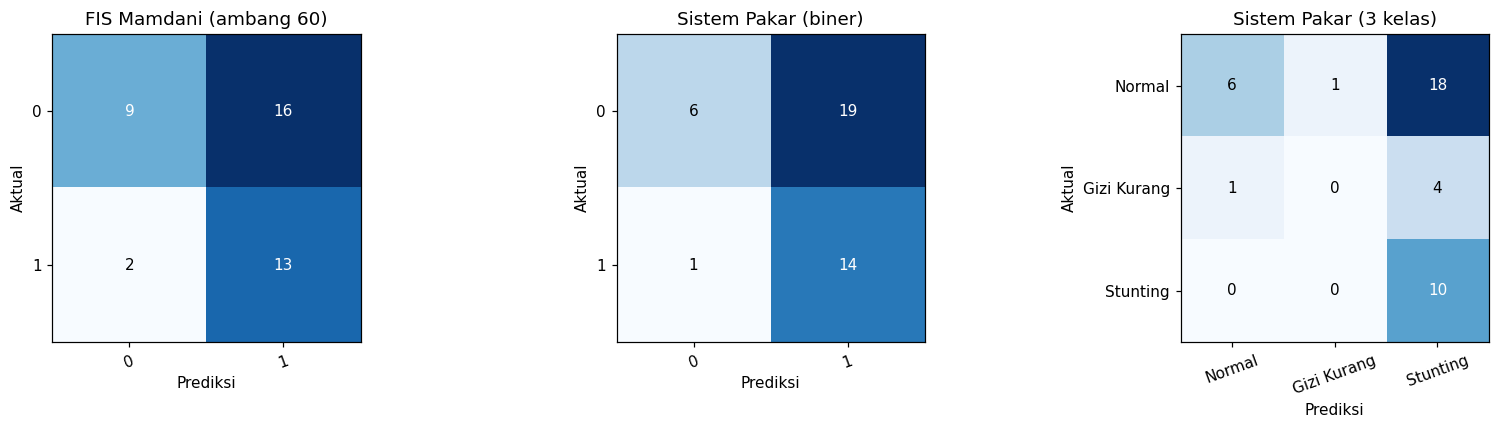

Akurasi Sistem Pakar 3 kelas: 40.0%


In [12]:
# Evaluasi FIS dan Sistem Pakar pada data uji (biner) + grafik
HASIL["FIS Mamdani"]   = hitung_metrik(te["y"], te["pred_fis"], te["skor_fis"])
HASIL["Sistem Pakar"]  = hitung_metrik(te["y"], te["pred_pakar"], te["pred_pakar"])   # AUC dari prediksi biner
SKOR["FIS Mamdani"], PRED["FIS Mamdani"]   = te["skor_fis"].values, te["pred_fis"].values
SKOR["Sistem Pakar"], PRED["Sistem Pakar"] = te["pred_pakar"].values, te["pred_pakar"].values

kelas = ["Normal", "Gizi Kurang", "Stunting"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plot_cm(ax[0], te["y"], te["pred_fis"], [0, 1], f"FIS Mamdani (ambang {AMBANG})")
plot_cm(ax[1], te["y"], te["pred_pakar"], [0, 1], "Sistem Pakar (biner)")
plot_cm(ax[2], te["Status_gizi"], te["status_pakar"], kelas, "Sistem Pakar (3 kelas)")
plt.tight_layout(); plt.show()
print(f"Akurasi Sistem Pakar 3 kelas: {accuracy_score(te['Status_gizi'], te['status_pakar'])*100:.1f}%")

=== FIS untuk B03 ===
z_BB = -2.92, z_TB = -2.59
Fuzzifikasi BB/U: {'rendah': 1.0, 'normal': 0.271, 'tinggi': 0.0}
Fuzzifikasi TB/U: {'rendah': 1.0, 'normal': 0.352, 'tinggi': 0.0}
  R1: BB rendah AND TB rendah -> skor tinggi  (alpha = 1.000)
  R2: BB rendah AND TB normal -> skor sedang  (alpha = 0.352)
  R4: BB normal AND TB rendah -> skor sedang  (alpha = 0.271)
  R5: BB normal AND TB normal -> skor rendah  (alpha = 0.271)
Alpha per output: {'tinggi': 1.0, 'sedang': 0.352, 'rendah': 0.271}
Skor risiko (centroid) = 57.91


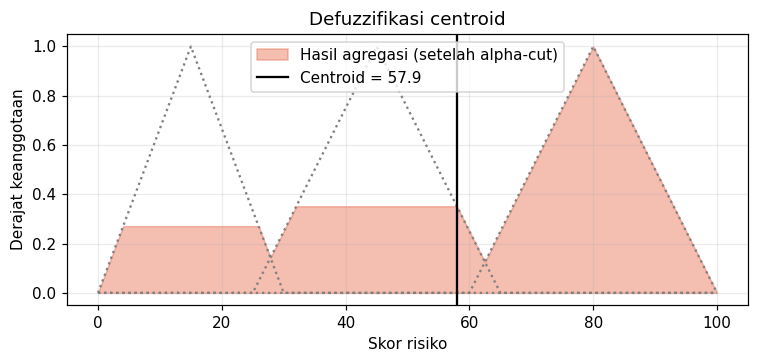


=== Sistem pakar (forward chaining) untuk B02 ===
Iterasi 1 | WM = ['asi_tidak', 'bb_normal', 'lila_cukup', 'skor_rendah', 'tb_pendek']
   match = ['R8']
   fired = ['R8'] | fakta baru = ['dx_normal']
Iterasi 2 | WM = ['asi_tidak', 'bb_normal', 'dx_normal', 'lila_cukup', 'skor_rendah', 'tb_pendek']
   match = []
Diagnosa: Normal | Rekomendasi: Pertahankan pola makan, pantau bulanan


In [13]:
# Demo: tracing contoh balita (cocokkan dengan hitungan manualmu)
# B03 (Budi, 18 bln, BB 7,4 kg, TB 74 cm) memakai nilai median/SD yang diberikan di naskah soal
z_bb_b03 = (7.4 - 10.9) / 1.2
z_tb_b03 = (74 - 82.3) / 3.2
print("=== FIS untuk B03 ===")
jelaskan_fis(z_bb_b03, z_tb_b03)

print("\n=== Sistem pakar (forward chaining) untuk B02 ===")
r = df[df["ID"] == "B02"].iloc[0]
jelaskan_pakar(r["z_bb"], r["z_tb"], r["lila"], r["asi"], r["skor_fis"])

# Perbandingan akhir: XGBoost, Decision Tree, FIS, dan Sistem Pakar (data uji)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
XGBoost (Tuned),85.0,90.9,66.7,76.9,84.7
Decision Tree (Baseline),77.5,87.5,46.7,60.9,79.6
FIS Mamdani,55.0,44.8,86.7,59.1,72.9
Sistem Pakar,50.0,42.4,93.3,58.3,58.7


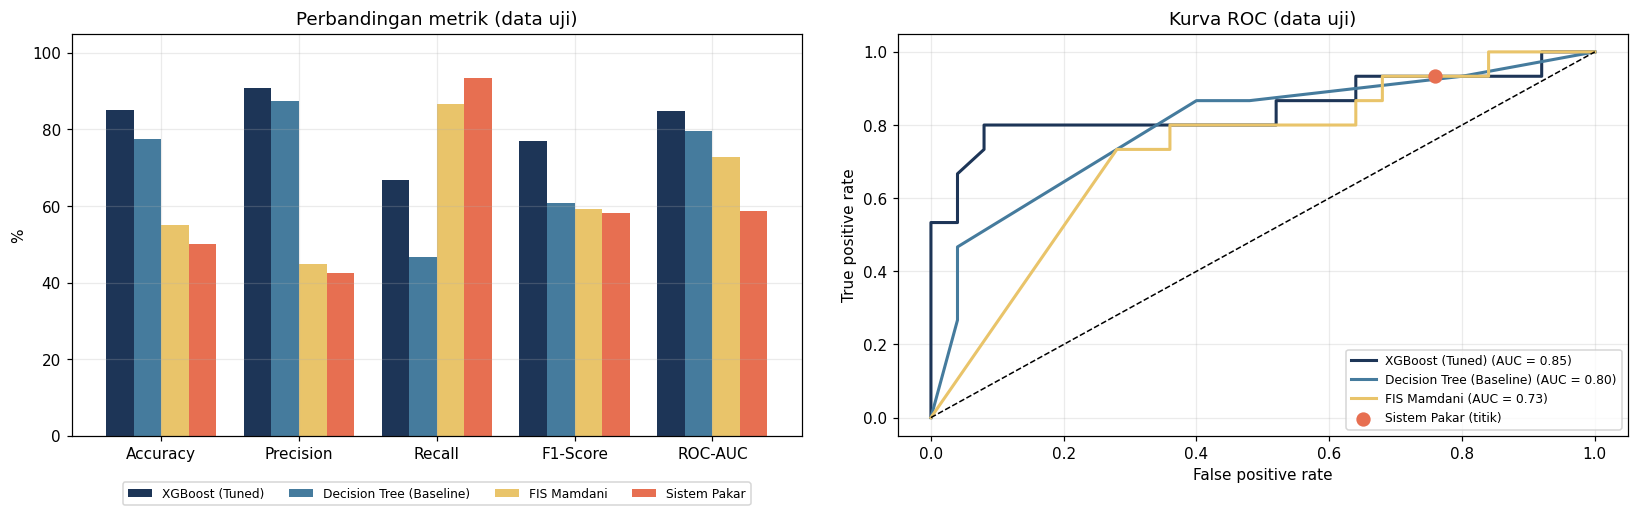

In [14]:
tabel_akhir = (pd.DataFrame(HASIL).T * 100).round(1)
tabel_akhir = tabel_akhir.loc[["XGBoost (Tuned)", "Decision Tree (Baseline)", "FIS Mamdani", "Sistem Pakar"]]
display(tabel_akhir)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
tabel_akhir.T.plot(kind="bar", ax=ax[0], width=0.8, color=["#1d3557", "#457b9d", "#e9c46a", "#e76f51"])
ax[0].set_ylabel("%"); ax[0].set_ylim(0, 105); ax[0].set_title("Perbandingan metrik (data uji)")
ax[0].tick_params(axis="x", rotation=0)
ax[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)

for nama, warna in [("XGBoost (Tuned)", "#1d3557"), ("Decision Tree (Baseline)", "#457b9d"), ("FIS Mamdani", "#e9c46a")]:
    fpr, tpr, _ = roc_curve(yte if nama != "FIS Mamdani" else te["y"], SKOR[nama])
    ax[1].plot(fpr, tpr, color=warna, lw=2, label=f"{nama} (AUC = {HASIL[nama]['ROC-AUC']:.2f})")
cm_p = confusion_matrix(te["y"], te["pred_pakar"], labels=[0, 1])
ax[1].scatter([cm_p[0, 1] / cm_p[0].sum()], [cm_p[1, 1] / cm_p[1].sum()], color="#e76f51", s=70, zorder=5, label="Sistem Pakar (titik)")
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("Kurva ROC (data uji)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()